# Follow D1 as it looks closer

**One notebook, one worked example, six visible steps.** All images and actual API responses are embedded in this file. No repository, local server, data downloads, or helper files are needed.

**Jupyter:** run all cells. The last cell contains an interactive **Play / Next / Back** viewer with animated zoom, pan, prompts, probabilities, and boxes. The individual cells also save static intermediate images, so the explanation remains readable when scripts are disabled. Trust this notebook if Jupyter blocks the interactive output.

The default replays a real `liquid/d1.2` run recorded on **17 November 2026**. To make fresh calls, change `LIVE` below to `True`; a hidden prompt requests your OpenRouter key unless `OPENROUTER_API_KEY` is set. Up to three calls are billed. No key is embedded or saved.

This example was chosen because its recorded answers follow the full crop path. A fresh model run may choose differently. **Purple rectangles are computed grid regions, not native bounding-box predictions.**

In [1]:
LIVE = False                       # True makes fresh OpenRouter calls
MODEL = "liquid/d1.2"
import base64, copy, hashlib, html, io, json, math, os, time, urllib.request, urllib.error, zlib
from datetime import datetime, timezone
from getpass import getpass
from IPython.display import display, HTML, Markdown
try:
    from PIL import Image, ImageDraw
except ImportError:                 # The only extra package; usually already installed
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pillow"])
    from PIL import Image, ImageDraw
KEY = (os.environ.get("OPENROUTER_API_KEY") or getpass("OpenRouter key (hidden): ")) if LIVE else ""

### Included data and small utilities

Run these two folded cells unchanged. The first contains the images, recorded responses, and offline viewer. The second handles display and the API request. The inspection logic is in the short numbered steps below. Only a missing Pillow installation needs a package download; replay otherwise works offline.

In [2]:
#@title Embedded images, real responses, and viewer — run unchanged
BUNDLE = json.loads(zlib.decompress(base64.b64decode('...')))

In [3]:
#@title Display and API utilities — run unchanged
trace, frames = {}, []
def decode(url):
    return Image.open(io.BytesIO(base64.b64decode(url.split(",", 1)[1]))).convert("RGB")
def encode(im):
    b = io.BytesIO(); im.save(b, format="JPEG", quality=95)
    return "data:image/jpeg;base64," + base64.b64encode(b.getvalue()).decode()
def pretty(value):
    return "<pre style='white-space:pre-wrap;overflow-wrap:anywhere'>" + html.escape(json.dumps(value, indent=2)) + "</pre>"
def ask(name, images, prompt=None, questions=None):
    saved = BUNDLE["records"][name]
    prompt, questions = prompt or saved["prompt"], questions or saved["questions"]
    if not LIVE and (MODEL != saved["model"] or prompt != saved["prompt"] or questions != saved["questions"] or
                    [hashlib.sha256(im.tobytes()).hexdigest() for im in images] != saved["pixel_hashes"]):
        raise ValueError("Inputs changed. Use LIVE=True for new answers, or restore the recorded example.")
    urls = [encode(im) for im in images] if LIVE else saved["inputs"]
    display(Markdown("**Exact unmarked images sent, in order:**"), HTML("<div style='display:flex;gap:12px;flex-wrap:wrap'>" +
        "".join(f"<figure style='margin:0'><img src='{u}' width='300'><figcaption>Image {i+1}</figcaption></figure>" for i,u in enumerate(urls)) + "</div>"))
    display(Markdown("**Exact prompt:**\n\n" + prompt), HTML("<details open><summary>Exact typed questions</summary>" + pretty(questions) + "</details>"))
    body = {"model":MODEL, "state":[prompt, *({"type":"image_url", "image_url":{"url":u}} for u in urls)],
            "questions":questions, "provider":{"allow_fallbacks":False}}
    if LIVE:
        request = urllib.request.Request("https://openrouter.ai/api/alpha/decisions", json.dumps(body).encode(),
                   {"Authorization":"Bearer " + KEY, "Content-Type":"application/json"})
        started = time.perf_counter()
        try:
            with urllib.request.urlopen(request, timeout=90) as response: result = json.load(response)
        except urllib.error.HTTPError as error:
            raise RuntimeError(f"OpenRouter HTTP {error.code}: " + error.read().decode()[:400].replace(KEY,"[hidden]")) from None
        elapsed = (time.perf_counter() - started)*1000
        result.pop("user_id", None)
    else:
        result, elapsed = copy.deepcopy(saved["response"]), saved["latency_ms"]
    trace[name] = dict(prompt=prompt, questions=questions, response=result, latency_ms=elapsed, inputs=urls,
                       recorded_at=datetime.now(timezone.utc).isoformat() if LIVE else saved["recorded_at"])
    display(Markdown(f"**{'Fresh' if LIVE else 'Recorded'} response · {elapsed:.2f} ms**"), HTML(pretty(result["answers"])))
    display(HTML("<details><summary>Full raw response, tokens and cost</summary>" + pretty(result) + "</details>"))
    return result["answers"]
CELLS = "top_left top top_right left centre right bottom_left bottom bottom_right".split()
def cell_box(choice, width, height):
    if choice == "not_visible": return None
    row, col = divmod(CELLS.index(choice), 3)
    return [col*width/3, row*height/3, (col+1)*width/3, (row+1)*height/3]
def step(title, description, image, window=None, boxes=(), grid=False, call=None):
    window = window or [0, 0, *original.size]
    record = trace.get(call, {})
    f = dict(title=title, description=description, window=window, boxes=list(boxes), grid=grid,
             input_url=record.get("inputs", [encode(image)])[-1])
    f.update({k:record[k] for k in ["prompt","questions","response","latency_ms"] if k in record})
    if len(record.get("inputs", []))==2: f["reference_url"] = record["inputs"][0]
    frames.append(f)
    marked = image.copy(); draw = ImageDraw.Draw(marked)
    if grid:
        for i in (1,2):
            draw.line((image.width*i/3,0,image.width*i/3,image.height), fill="#c4d9b3", width=2)
            draw.line((0,image.height*i/3,image.width,image.height*i/3), fill="#c4d9b3", width=2)
    for box in boxes:
        x0,y0,x1,y1 = box["bounds"]
        draw.rectangle((x0-window[0], y0-window[1], x1-window[0], y1-window[1]), outline=box["color"], width=3)
    display(Markdown("**" + title + "** — " + description), marked)
def mark(bounds, label, color="#b098ed"):
    return {"bounds":bounds, "label":label, "color":color}

## 1 · Start with the image

We use Liquid's public `chewinggum/03.jpg` sample and its known-good reference. We preserve original pixels throughout. Dataset annotations will be shown only at the end.

In the interactive viewer, **drag** to pan and **scroll / + / −** to zoom. Those controls change your view, not the image submitted to D1.

**Original** — Start with the complete specimen. No API call yet.

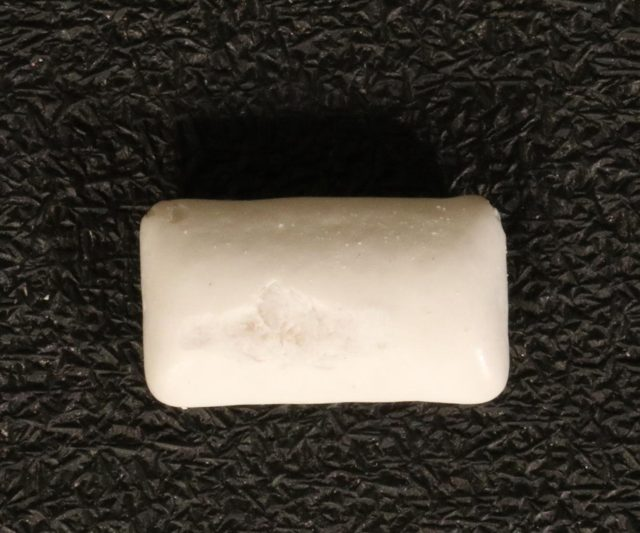

Original size: 640 × 533 pixels


In [4]:
original, reference = decode(BUNDLE["image"]), decode(BUNDLE["reference"])
W, H = original.size
step("Original", "Start with the complete specimen. No API call yet.", original)
print("Original size:", W, "×", H, "pixels")

## 2 · Ask whether a defect is visible

Image 1 is the healthy reference; image 2 is our specimen. `noul` returns a defect score and `choice` returns a defect category. Every image, prompt, question and response appears below. These scores are model outputs, not measured accuracy.

**Exact unmarked images sent, in order:**


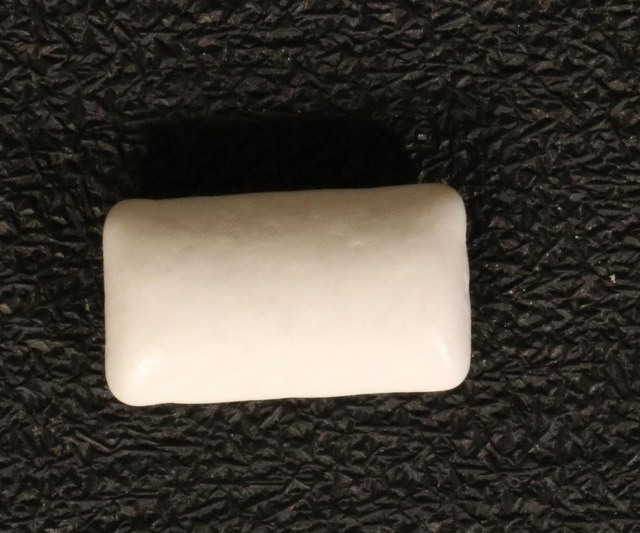
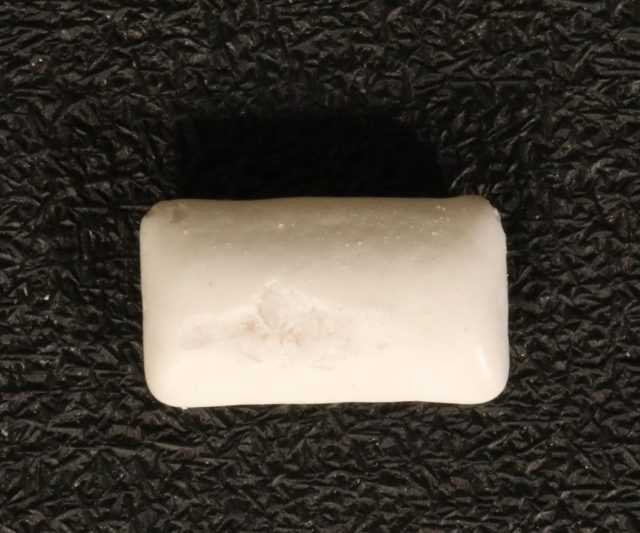

**Exact prompt:**

Visual inspection. Object category: piece of chewing gum. Inspection target: visible manufacturing defects. Image 1 is a known-good reference. Image 2 is the inspection image. Compare image 2 with image 1.

**Recorded response · 1116.58 ms**

**Compare** — Compare the specimen with the healthy reference.

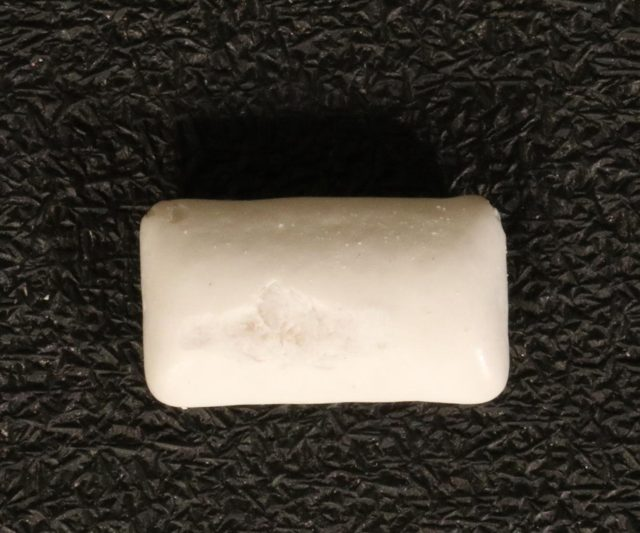

In [5]:
comparison = ask("classification", [reference, original])
step("Compare", "Compare the specimen with the healthy reference.", original, call="classification")

## 3 · Choose where to look

Ask D1 for one cell of an imaginary **3 × 3 grid**, or `not_visible`. The model receives the **unmarked image**. We draw the grid and selected cell only afterwards. A classification score does not force a location.

**Exact unmarked images sent, in order:**


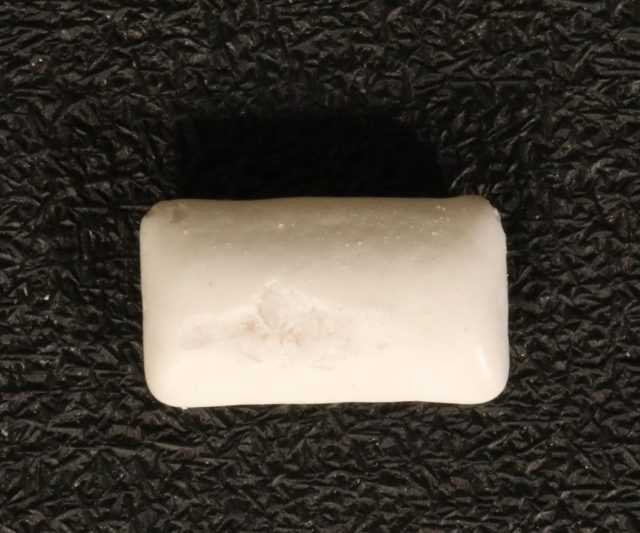

**Exact prompt:**

Visual inspection. Object category: piece of chewing gum. Inspection target: visible manufacturing defects. Imagine a 3 by 3 grid of equal rectangular cells over the entire submitted image. Rows run top to bottom; columns run left to right. No grid is drawn on the image.

**Recorded response · 970.64 ms**

**Locate** — D1 chooses a coarse cell; this is not a tight detection box.

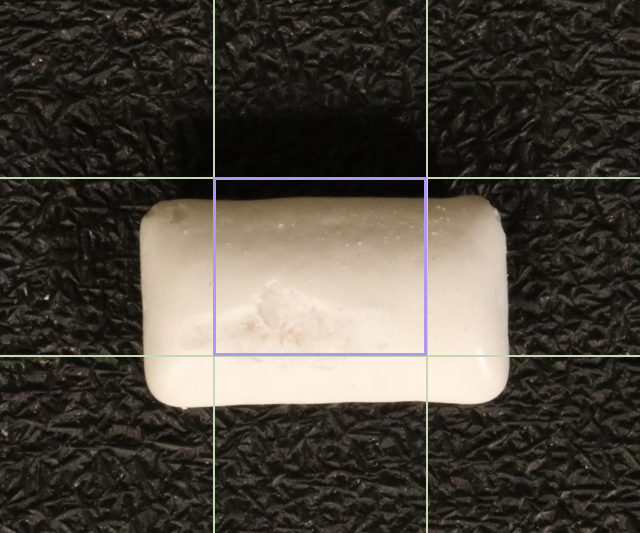

In [6]:
coarse = ask("coarse_grid", [original])
coarse_box = cell_box(coarse["grid"]["choice"], W, H)
step("Locate", "D1 chooses a coarse cell; this is not a tight detection box.", original,
     grid=True, boxes=[mark(coarse_box, "D1 coarse cell")] if coarse_box else [], call="coarse_grid")

## 4 · Crop and zoom into the selected region

Expand the chosen cell by half a cell on each side, clip to the original image, then crop. Here the expected recorded crop is **(106, 88) to (534, 445)**: 428 × 357 pixels. The viewer animates this exact change in scale.

This crop changes the pixels in the next request. It is different from merely magnifying the browser view. A `not_visible` answer stops the search.

Crop bounds: [106, 88, 534, 445] — size: (428, 357)


**Crop & zoom** — Crop original pixels, preserving some surrounding context.

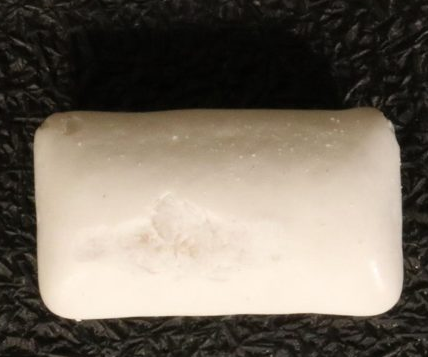

In [7]:
cropped, crop_bounds, final_box = None, None, None
if coarse_box:
    l, t, r, b = coarse_box
    crop_bounds = [math.floor(max(0,l-W/6)), math.floor(max(0,t-H/6)),
                   math.ceil(min(W,r+W/6)), math.ceil(min(H,b+H/6))]
    cropped = original.crop(crop_bounds)
    print("Crop bounds:", crop_bounds, "— size:", cropped.size)
    step("Crop & zoom", "Crop original pixels, preserving some surrounding context.", cropped, window=crop_bounds)
else:
    print("No visible cell selected: no crop or finer API call.")

## 5 · Ask again inside the crop

The prompt now explicitly calls this a **cropped detail** and says to ignore missing content outside it. D1 selects a finer cell. We convert its crop-relative coordinates back to original pixels by adding the crop's top-left offset.

**Exact unmarked images sent, in order:**


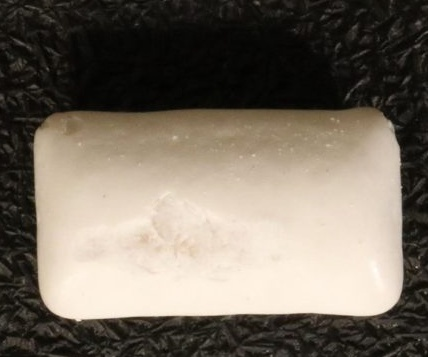

**Exact prompt:**

Visual inspection. Object category: piece of chewing gum. Inspection target: visible manufacturing defects. The inspection image is a cropped detail of a larger specimen. Judge only the visible region; do not treat content outside the crop as missing. Imagine a 3 by 3 grid of equal rectangular cells over the entire submitted image. Rows run top to bottom; columns run left to right. No grid is drawn on the image.

**Recorded response · 955.67 ms**

**Refine** — A second choice narrows the region inside the crop.

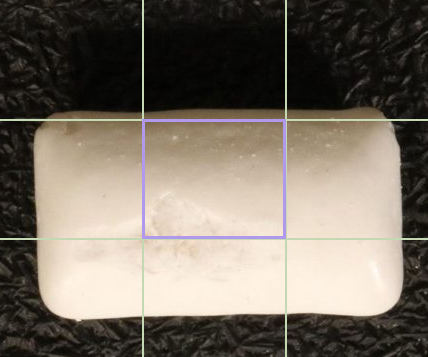

In [8]:
if cropped is not None:
    fine = ask("fine_grid", [cropped])
    relative = cell_box(fine["grid"]["choice"], *cropped.size)
    if relative:
        x, y = crop_bounds[:2]
        final_box = [x+relative[0], y+relative[1], x+relative[2], y+relative[3]]
    step("Refine", "A second choice narrows the region inside the crop.", cropped, window=crop_bounds,
         grid=True, boxes=[mark(final_box, "D1 fine cell")] if final_box else [], call="fine_grid")

## 6 · Draw the result on the original

**Purple:** region computed from the two D1 choices. **Gold:** dataset annotations, never supplied to D1. Their overlap is imperfect: a grid cell is not an object boundary. A missing region stays missing.

The following timing is the sum of recorded HTTP calls, including network time; it excludes display time and is not a latency benchmark.

**Map back** — Return to the original scale and compare independent overlays.

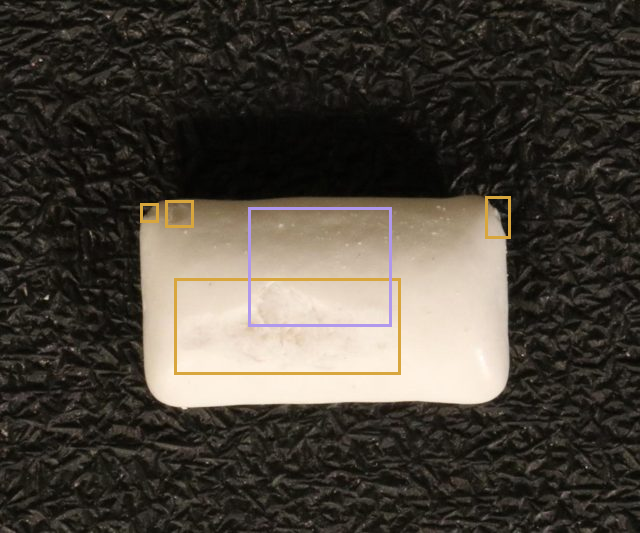

Original-pixel region: [248.66666666666666, 207.0, 391.3333333333333, 326.0]
API calls: 3 | Sum of HTTP times: 3042.89 ms
API-reported USD: 5.3e-05


In [9]:
gold = [mark([l*W,t*H,r*W,b*H], "Dataset annotation", "#d8a63d") for l,t,r,b in BUNDLE["truth"]]
prediction = [mark(final_box, "Grid-derived region")] if final_box else []
step("Map back", "Return to the original scale and compare independent overlays.", original, boxes=gold+prediction)
print("Original-pixel region:", final_box)
print("API calls:", len(trace), "| Sum of HTTP times:", round(sum(s["latency_ms"] for s in trace.values()),2), "ms")
print("API-reported USD:", sum(s["response"].get("usage",{}).get("cost",0) for s in trace.values()))

## Play the complete path

Use **Next / Back**, click a step name, or press **Play**. Watch the camera zoom into the crop, see the selected grid cell, then return to the original with the final box. The right panel always shows the corresponding unmarked input, prompt, answer probabilities, and timing. Use **Reset to step** after manual pan/zoom.

This viewer is completely offline. If your notebook frontend suppresses scripts, the numbered cells above still show every intermediate result.

<iframe title="D1 crop walkthrough" sandbox="allow-scripts" style="width:100%;height:920px;border:0" srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Visual inspection walkthrough</title>
<style>
:root{color-scheme:light;--paper:#f6f8f2;--surface:#fff;--ink:#263b2d;--muted:#667665;--line:#d6e0d0;--green:#345e42;--pale:#e9f0e3;--mono:ui-monospace,SFMono-Regular,Consolas,monospace}*{box-sizing:border-box}body{margin:0;background:var(--paper);color:var(--ink);font:14px/1.5 -apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif}button,summary{touch-action:manipulation}button{font:inherit;border:1px solid var(--line);border-radius:6px;background:var(--surface);color:var(--ink);padding:7px 11px;cursor:pointer}button:hover:not(:disabled){background:var(--pale);border-color:#9aae8e}button:active:not(:disabled){transform:translateY(1px)}button:disabled{opacity:.4;cursor:default}button:focus-visible,summary:focus-visible,canvas:focus-visible{outline:3px solid #8fa977;outline-offset:2px}.app{max-width:1440px;margin:auto;padding:18px 22px 20px}.header{display:flex;justify-content:space-between;gap:18px;align-items:start;margin-bottom:15px}.eyebrow{font:10px var(--mono);letter-spacing:1.5px;color:var(--muted);margin:0 0 7px}h1{font-size:22px;letter-spacing:-.6px;margin:0;font-weight:620}h2{font-size:17px;letter-spacing:-.3px;margin:0 0 5px}h3{font-size:12px;margin:0;font-weight:650}p{margin:0}.muted,.caption{color:var(--muted)}.caption{font-size:11px;line-height:1.5}.metadata{text-align:right;font:10px/1.7 var(--mono);color:var(--muted);max-width:38%;overflow-wrap:anywhere}.path{display:flex;gap:5px;overflow-x:auto;padding:3px 2px 10px;margin-bottom:12px;scrollbar-width:thin}.path button{display:flex;align-items:center;gap:7px;text-align:left;white-space:nowrap;padding:8px 10px;font-size:11px}.path button span{font:10px var(--mono);color:var(--muted)}.path button[aria-current=step]{background:var(--green);color:white;border-color:var(--green)}.path button[aria-current=step] span{color:#d1e2c9}.layout{display:grid;grid-template-columns:minmax(0,1.35fr) minmax(300px,1fr);gap:18px;align-items:start}.left,.right{min-width:0}.viewer-shell{border:1px solid #c7d5be;border-radius:9px;overflow:hidden;background:#edf2e8}.viewer-toolbar{display:flex;justify-content:space-between;align-items:center;gap:10px;padding:9px 11px;border-bottom:1px solid var(--line);font-size:11px}.viewer-toolbar>div{display:flex;gap:5px;align-items:center}.viewer-toolbar button{padding:4px 9px;font-size:12px}.viewer-toolbar output{font:10px var(--mono);min-width:45px;text-align:center}.canvas-wrap{position:relative;height:340px;min-height:220px}.canvas-wrap canvas{display:block;width:100%;height:100%;cursor:grab;touch-action:none}.canvas-wrap canvas.dragging{cursor:grabbing}.canvas-note{position:absolute;bottom:10px;left:50%;transform:translateX(-50%);max-width:90%;text-align:center;padding:5px 9px;background:#f9fbf3ed;border:1px solid #d6e0d0;border-radius:5px;color:var(--muted);font-size:10px;pointer-events:none;white-space:nowrap}.viewer-footer{display:flex;justify-content:space-between;gap:10px;padding:8px 11px;border-top:1px solid var(--line);font:10px var(--mono);color:var(--muted)}.playback{display:flex;gap:7px;align-items:center;margin:12px 0}.playback button{font-size:12px}.playback .primary{background:var(--green);color:white;border-color:var(--green);min-width:82px}.playback output{margin-left:auto;font:11px var(--mono);color:var(--muted)}.step-copy{border-top:1px solid var(--line);padding-top:13px;min-height:70px}.step-copy p{font-size:12px;color:var(--muted);max-width:75ch}.legend{display:flex;flex-wrap:wrap;gap:6px 14px;margin:10px 0 8px;font-size:10px;color:var(--muted)}.legend span{display:flex;align-items:center;gap:5px}.legend i{display:inline-block;width:9px;height:9px;border:1px solid currentColor}.note{font-size:11px;color:var(--muted);padding:10px 12px;back
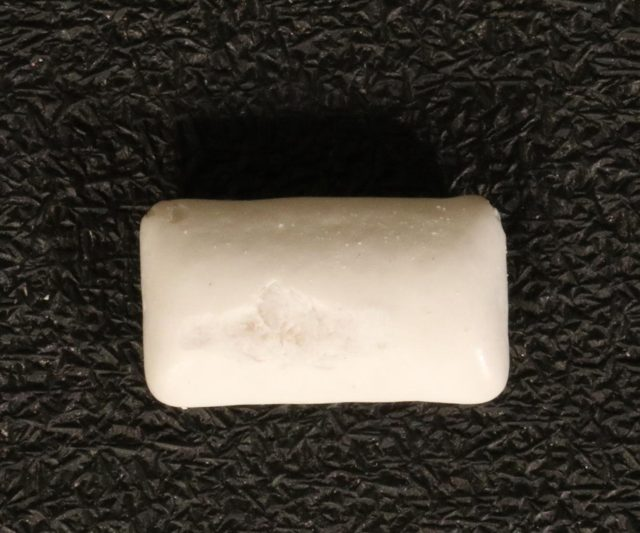
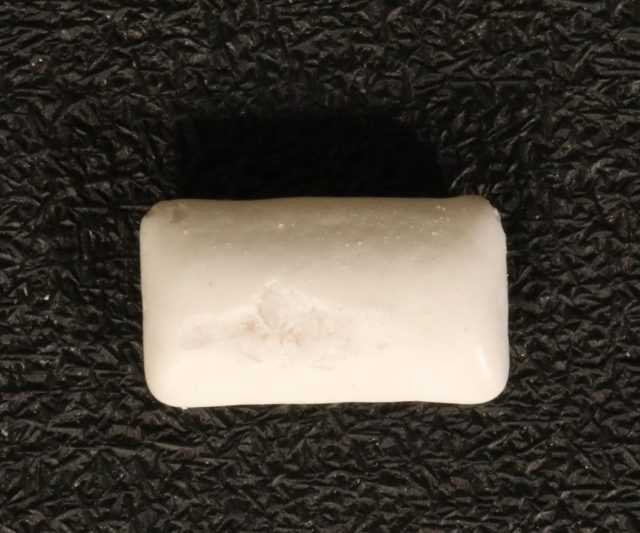
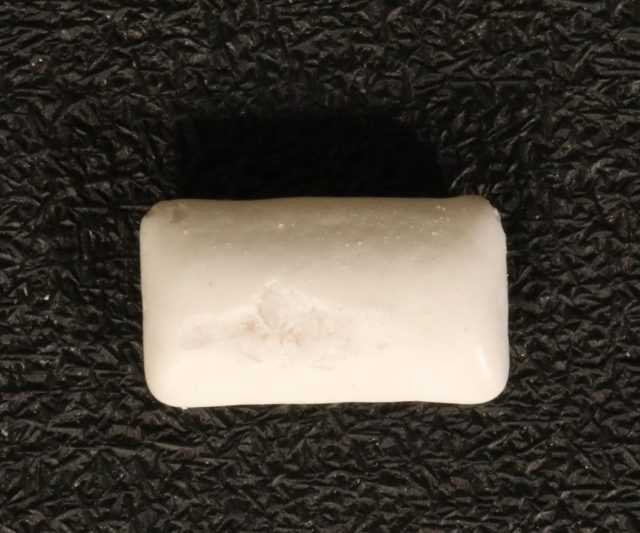
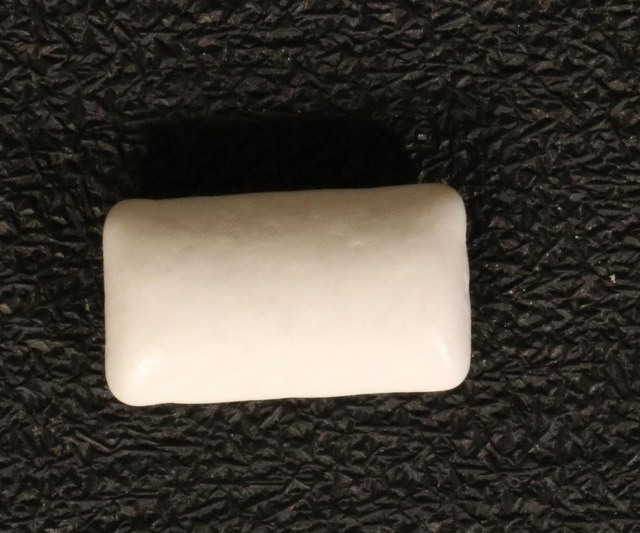
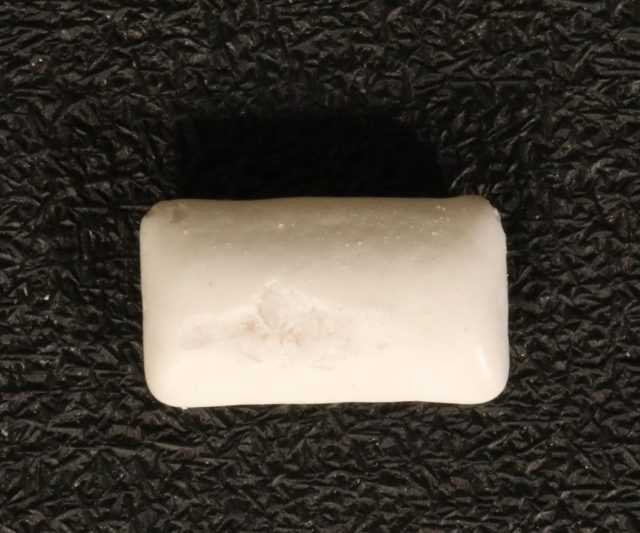
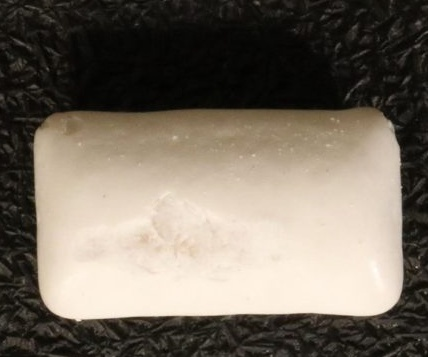
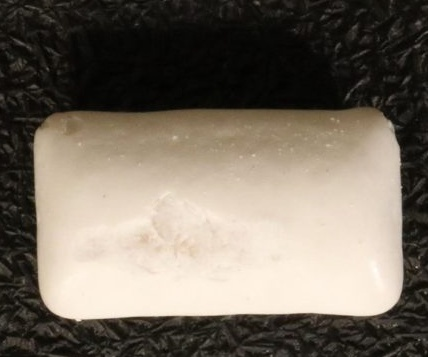
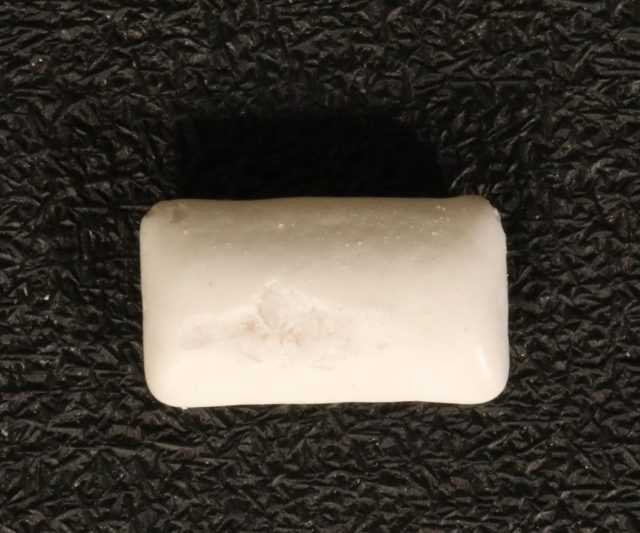

In [10]:
walkthrough = dict(model=MODEL, recorded_at=trace["classification"]["recorded_at"],
                   original_url=BUNDLE["image"], original_size=[W,H], frames=frames)
viewer = BUNDLE["viewer_template"].replace("__WALKTHROUGH_DATA__", json.dumps(walkthrough).replace("<", "\\u003c"))
display({'text/html': '<iframe title="D1 crop walkthrough" sandbox="allow-scripts" style="width:100%;height:920px;border:0" srcdoc="' +
             html.escape(viewer, quote=True) + '"></iframe>'}, raw=True)

### Provenance and what this does not establish

Actual recorded responses: `liquid/d1.2-20261116`, served by Liquid through [OpenRouter Decisions](https://openrouter.ai/docs/guides/community/multimodal-decisions), 17 November 2026. The full three-call trace is embedded. Changing prompts or inputs in replay raises an error instead of silently reusing mismatched answers.

Image and reference: [Liquid inspection sample](https://d1.liquid.ai/demos/data/inspection/chewinggum/03.jpg), [reference](https://d1.liquid.ai/demos/data/inspection/chewinggum/ref.jpg), [manifest](https://d1.liquid.ai/demos/data/inspection/index.json). Images correspond to Amazon Science's [VisA dataset](https://registry.opendata.aws/visa/), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/): Yang Zou, Jongheon Jeong, Latha Pemula, Dongqing Zhang and Onkar Dabeer. Liquid supplies the sample selection and box annotations. This is a teaching example, not the full benchmark.

**APERTURE extension:** the current path has a fixed maximum of two grid decisions. A future experiment could add `keep this scale / inspect a child / recover wider context / unresolved` actions while keeping APERTURE's concept scorer fixed. Adaptive satellite-image scale selection has not been tested here.